# 修复代码，再用测试验证 / Code-repair Agent

我们把函数 `solve(x, y)` 的减法错误修成加法或乘法。策略先阅读任务，选择一个补丁，
调用 Python 运行公开测试，再决定提交或继续修改。提交后还有独立测试，
因此只记住一个公开样例的补丁不能取得完整奖励。

默认 CPU、两个种子、160 次更新。策略从三个可信补丁模板中选择，
用于观察测试反馈怎样改变多轮决策。配套章节还提供 rLLM 训练流程。


In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for name, spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import os
from pathlib import Path
import numpy as np
import torch

torch.set_num_threads(1)
OUTPUT = Path(os.getenv("HANDS_ON_LAB_OUTPUT", "lab-output")) / "agentic-code"
OUTPUT.mkdir(parents=True, exist_ok=True)

from functools import lru_cache
import tempfile

training = [{"kind": i % 2, "x": i + 2, "y": i % 5 + 2} for i in range(24)]
heldout = [{"kind": i % 2, "x": i + 40, "y": i % 7 + 2} for i in range(16)]
print({"train_tasks": len(training), "heldout_tasks": len(heldout)})


{'train_tasks': 24, 'heldout_tasks': 16}


## 1. 测试必须实际执行 / Execute the tests

下面的工具把候选函数写入临时文件，并在独立 Python 进程里执行断言。
相同源码与相同测试使用缓存，避免重复启动进程；首次结果始终来自实际执行。
候选代码由三个模板生成，测试进程设置两秒超时。


In [2]:
@lru_cache(maxsize=4096)
def python_tests(source, cases):
    assertions = [f"assert solve({x}, {y}) == {answer}" for x, y, answer in cases]
    program = source + "\n" + "\n".join(assertions) + "\nprint('passed')\n"
    with tempfile.TemporaryDirectory(prefix="agent-test-") as folder:
        path = Path(folder) / "candidate.py"
        path.write_text(program)
        try:
            result = subprocess.run([sys.executable, "-I", "-S", str(path)],
                                    capture_output=True, text=True, timeout=2)
            return {"passed": result.returncode == 0, "exit_code": result.returncode,
                    "output": (result.stdout + result.stderr)[-300:]}
        except subprocess.TimeoutExpired:
            return {"passed": False, "exit_code": -1, "output": "timeout"}


def expected(task, x, y):
    return x + y if task["kind"] == 0 else x * y


def patch_source(task, action):
    expression = {1: "x + y", 2: "x * y", 3: str(expected(task, task["x"], task["y"]))}
    if action == 3:
        expression[3] += f" if x == {task['x']} else 0"
    return "def solve(x, y):\n    return " + expression[action] + "\n"


demo_task = training[0]
overfit = patch_source(demo_task, 3)
public_case = ((demo_task["x"], demo_task["y"], expected(demo_task, 2, 2)),)
private_case = ((5, 3, expected(demo_task, 5, 3)),)
print(overfit, python_tests(overfit, public_case), python_tests(overfit, private_case))
assert python_tests(overfit, public_case)["passed"]
assert not python_tests(overfit, private_case)["passed"]


def solve(x, y):
    return 4 if x == 2 else 0
 {'passed': True, 'exit_code': 0, 'output': 'passed\n'} {'passed': False, 'exit_code': 1, 'output': 'Traceback (most recent call last):\n  File "/var/folders/wd/sss3gvxn5j9_vskh6mp8x89r0000gn/T/agent-test-d7wquyx7/candidate.py", line 4, in <module>\n    assert solve(5, 3) == 8\n           ^^^^^^^^^^^^^^^^\nAssertionError\n'}


## 2. 公开样例通过，还要检查独立样例 / Public and private tests

任务说明会告诉策略需要加法还是乘法。公开测试的反馈进入下一步观测，
独立测试的答案仅在终局验证器中使用。合法动作约束提供阅读、修改、测试、提交的接口协议。
训练集与评估集使用不同输入数字，分别检查加法和乘法函数。


In [3]:
class CodeEnvironment:
    actions = ["inspect", "patch_add", "patch_multiply", "patch_overfit", "test", "submit"]
    max_turns = 7

    def __init__(self, task):
        self.task, self.stage = task, 0
        self.source = "def solve(x, y):\n    return x - y\n"
        self.feedback, self.success = False, False

    def observe(self):
        state = [float(self.stage > 0 and self.task["kind"] == k) for k in range(2)]
        state += [float(self.stage == k) for k in range(4)] + [float(self.feedback)]
        legal = [False] * len(self.actions)
        for action in [[0], [1, 2, 3], [1, 2, 3, 4], [1, 2, 3, 5]][self.stage]:
            legal[action] = True
        return state, legal

    def step(self, action):
        assert self.observe()[1][action]
        task = self.task
        if action == 0:
            self.stage = 1
            return -0.01, False, {"spec": "sum" if task["kind"] == 0 else "product",
                                  "source": self.source,
                                  "public_case": [task["x"], task["y"],
                                      expected(task, task["x"], task["y"])]}
        if action in [1, 2, 3]:
            self.source, self.stage, self.feedback = patch_source(task, action), 2, False
            return -0.01, False, {"source": self.source}
        if action == 4:
            cases = ((task["x"], task["y"], expected(task, task["x"], task["y"])),)
            result = python_tests(self.source, cases)
            self.feedback, self.stage = result["passed"], 3
            return -0.01, False, result
        inputs = [(task["x"] + 1, task["y"] + 2), (-task["x"], task["y"]), (0, 3)]
        cases = tuple((x, y, expected(task, x, y)) for x, y in inputs)
        result = python_tests(self.source, cases)
        self.success = result["passed"]
        return float(self.success), True, {"private_tests": result}


assert {t["x"] for t in training}.isdisjoint(t["x"] for t in heldout)
print(CodeEnvironment.actions)


['inspect', 'patch_add', 'patch_multiply', 'patch_overfit', 'test', 'submit']


## 3. 训练有限补丁策略 / Train the patch policy

每个请求采样四条轨迹，以其余轨迹的平均回报作为基线。所有选择补丁与提交的动作
都参与轨迹损失，测试返回只作为下一轮输入。曲线比较相同评估请求上的贪心策略，
评估集只用于记录结果，训练预算固定，不按评估曲线挑选模型。


In [4]:
import random

import numpy as np
import torch
from torch import nn


class AgentPolicy(nn.Module):
    def __init__(self, dimensions, actions):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dimensions, 32), nn.Tanh(), nn.Linear(32, actions))

    def forward(self, observation, legal):
        logits = self.net(torch.tensor(observation, dtype=torch.float32))
        return logits.masked_fill(~torch.tensor(legal, dtype=torch.bool), -1e9)


def rollout(policy, task, factory, greedy=False, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    env = factory(task)
    logprobs, entropies, trace, rewards = [], [], [], []
    for turn in range(env.max_turns):
        observation, legal = env.observe()
        distribution = torch.distributions.Categorical(logits=policy(observation, legal))
        action = distribution.logits.argmax() if greedy else distribution.sample()
        logprobs.append(distribution.log_prob(action))
        entropies.append(distribution.entropy())
        reward, done, response = env.step(int(action))
        rewards.append(reward)
        trace.append({"turn": turn, "action": env.actions[int(action)],
                      "observation": response, "reward": reward})
        if done:
            break
    success = bool(env.success)
    if hasattr(env, "close"):
        env.close()
    return {"return": float(sum(rewards)), "success": success, "trace": trace,
            "logprob": torch.stack(logprobs).sum(),
            "entropy": torch.stack(entropies).sum()}


@torch.no_grad()
def evaluate_agent(policy, tasks, factory, greedy=True):
    samples = [rollout(policy, task, factory, greedy=greedy, seed=10000 + i)
               for i, task in enumerate(tasks)]
    return {"success_rate": float(np.mean([item["success"] for item in samples])),
            "return": float(np.mean([item["return"] for item in samples])),
            "mean_turns": float(np.mean([len(item["trace"]) for item in samples]))}


def train_agent(factory, tasks, heldout, seed, updates=160):
    torch.manual_seed(seed)
    rng = random.Random(seed)
    probe = factory(tasks[0])
    policy = AgentPolicy(len(probe.observe()[0]), len(probe.actions))
    if hasattr(probe, "close"):
        probe.close()
    before = evaluate_agent(policy, heldout, factory)
    optimizer = torch.optim.Adam(policy.parameters(), lr=3e-3)
    history = []
    for update in range(updates):
        losses = []
        for task in rng.choices(tasks, k=4):
            group = [rollout(policy, task, factory) for _ in range(4)]
            total = sum(item["return"] for item in group)
            for item in group:
                baseline = (total - item["return"]) / (len(group) - 1)
                advantage = item["return"] - baseline
                losses.append(-item["logprob"] * advantage - 0.002 * item["entropy"])
        optimizer.zero_grad()
        loss = torch.stack(losses).mean()
        loss.backward()
        nn.utils.clip_grad_norm_(policy.parameters(), 2)
        optimizer.step()
        if update % 20 == 0 or update == updates - 1:
            history.append({"update": update, "loss": float(loss.detach()),
                            **evaluate_agent(policy, heldout, factory)})
    after = evaluate_agent(policy, heldout, factory)
    return policy, before, after, history


def run_comparison(factory, training, heldout, output, updates=160):
    results, policies, curves = [], [], []
    for seed in [3, 7]:
        policy, before, after, history = train_agent(
            factory, training, heldout, seed, updates=updates)
        results.append({"seed": seed, "before": before, "after": after})
        policies.append(policy)
        curves.append(history)
    for row in results:
        print(row)
    import json
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for row, curve in zip(results, curves):
        ax.plot([point["update"] for point in curve],
                [point["success_rate"] for point in curve], label=f"seed {row['seed']}")
    ax.set(xlabel="Policy update", ylabel="Held-out greedy success", ylim=(-0.05, 1.05))
    ax.legend()
    fig.tight_layout()
    fig.savefig(output / "training.png", dpi=120)
    plt.show()
    trace = rollout(policies[0], heldout[0], factory, greedy=True)["trace"]
    print(json.dumps(trace, indent=2))
    torch.save(policies[0].state_dict(), output / "policy-seed3.pt")
    metrics = {"runs": results, "fixed_heldout_trace": trace,
               "train_tasks": len(training), "heldout_tasks": len(heldout),
               "updates": updates, "algorithm": "REINFORCE with leave-one-out baseline"}
    assert all(np.isfinite(row["after"]["return"]) for row in results)
    (output / "metrics.json").write_text(json.dumps(metrics, indent=2))
    return policies, metrics


print("Agent contract: observe → action → tool observation → next decision → verifier")


Agent contract: observe → action → tool observation → next decision → verifier


{'seed': 3, 'before': {'success_rate': 0.0, 'return': -0.07, 'mean_turns': 7.0}, 'after': {'success_rate': 1.0, 'return': 0.97, 'mean_turns': 4.0}}
{'seed': 7, 'before': {'success_rate': 0.0, 'return': -0.07, 'mean_turns': 7.0}, 'after': {'success_rate': 1.0, 'return': 0.97, 'mean_turns': 4.0}}


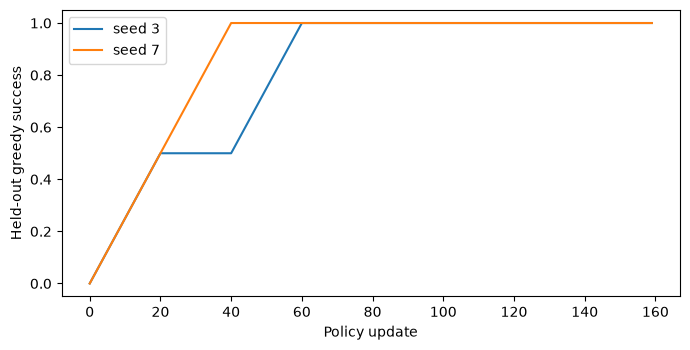

[
  {
    "turn": 0,
    "action": "inspect",
    "observation": {
      "spec": "sum",
      "source": "def solve(x, y):\n    return x - y\n",
      "public_case": [
        40,
        2,
        42
      ]
    },
    "reward": -0.01
  },
  {
    "turn": 1,
    "action": "patch_add",
    "observation": {
      "source": "def solve(x, y):\n    return x + y\n"
    },
    "reward": -0.01
  },
  {
    "turn": 2,
    "action": "test",
    "observation": {
      "passed": true,
      "exit_code": 0,
      "output": "passed\n"
    },
    "reward": -0.01
  },
  {
    "turn": 3,
    "action": "submit",
    "observation": {
      "private_tests": {
        "passed": true,
        "exit_code": 0,
        "output": "passed\n"
      }
    },
    "reward": 1.0
  }
]
Actual Python test invocations: 193


In [5]:
policies, metrics = run_comparison(CodeEnvironment, training, heldout, OUTPUT)
metrics["python_test_cache"] = python_tests.cache_info()._asdict()
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
assert metrics["python_test_cache"]["misses"] > 0
print("Actual Python test invocations:", metrics["python_test_cache"]["misses"])


## 完成检查 / Checklist
- [ ] 能找到真实子进程测试的输入、退出码与输出。
- [ ] 能解释只通过公开测试的补丁为什么仍会失败。
- [ ] 保存训练曲线、补丁轨迹、参数与测试调用次数。

## 练习 / Exercise
填入演示中记住公开答案的补丁在独立样例上的成功值。提示：这个补丁对其他输入返回零。


In [6]:
RUN_EXERCISE = False
answer = None
if RUN_EXERCISE:
    assert answer is False
else:
    print("Fill answer, then enable RUN_EXERCISE.")


Fill answer, then enable RUN_EXERCISE.


## 参考资料 / References
- [rLLM DeepCoder 实验](https://walkinglabs.github.io/hands-on-modern-rl/chapter22_agentic/rllm-deepcoder-lab)：语言模型代码 Agent 的完整训练路线。
- [Agentic 训练系统](https://walkinglabs.github.io/hands-on-modern-rl/chapter22_agentic/build-agentic-training-system)：环境、轨迹与模型更新的接口。


## 本次运行结果

CPU · Python 3.12.13 · 8.08 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/agentic-code-zh.html)
